# Ten motifs with balanced coverage on SOCAL_H_76_230427_014845.x

Ten motifs, each described by 5 components. A motif's coverage is the number of spectrogram columns its placements occupy. Those ten counts are within a factor of 4 (660 / 165 = 4). Every motif's mean residual gap is at least 0.1.

The gap at a placement is the unexplained fraction of the best other motif minus the unexplained fraction of the motif placed there. Motifs 0, 1, 3, 10, 11, 13, 14, and 17 are the tau=0.4 motifs, refit on the placements where that lead holds. Motif 100 is 60 leftover placements of motif 14. Motif 200 is a detection crop the other motifs do not explain.

Output directory: `/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_ten_balanced`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows

OUT = Path("/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_ten_balanced")
GPL = Path("/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy")
summary = json.loads((OUT / "summary.json").read_text())
windows = discover_windows(GPL)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
checks = summary["checks"]
print(f"accepted {summary['accepted']}")
print(
    f"recording coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}  "
    f"max count {summary['max_count']}"
)
for name, check in checks.items():
    value = check["value"]
    shown = f"{value:.3f}" if isinstance(value, float) else value
    print(f"{'pass' if check['ok'] else 'fail'}  {name} = {shown}")


accepted True
recording coverage 0.187  (3425 / 18270 columns)  motifs 10  placements 261  max count 1
pass  n_motifs = 10
pass  n_components = 5
pass  coverage_ratio = 4.000
pass  min_gap = 0.101


## Coverage and residual gaps

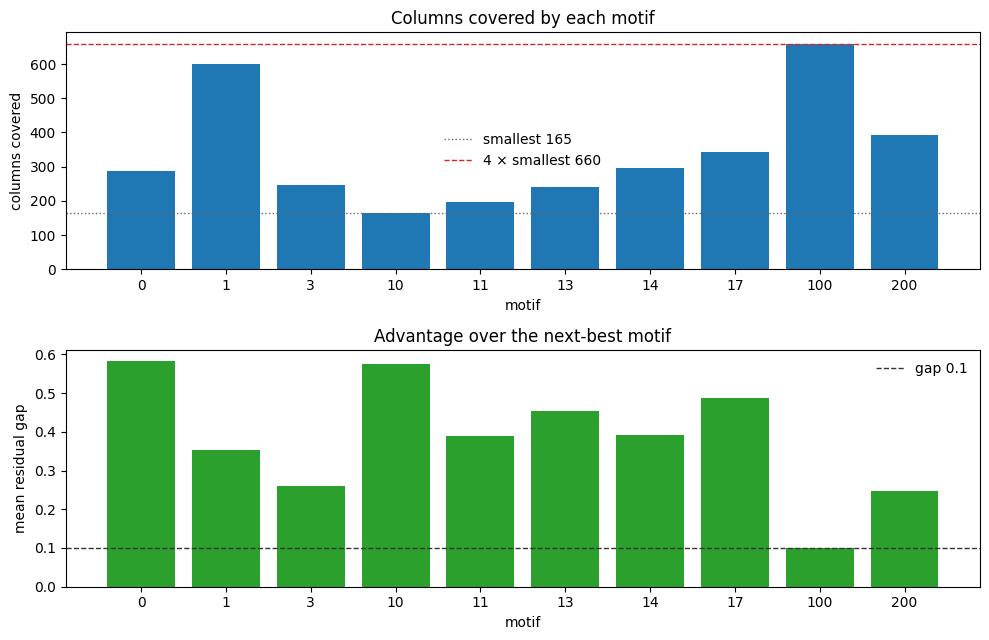

  id      n    cols      gap      own   runner  runner_id
   0     22     286    0.583    0.162    0.744  11
   1     60     600    0.354    0.258    0.611  100
   3     19     247    0.259    0.186    0.445  100
  10     11     165    0.574    0.116    0.691  3
  11     14     196    0.389    0.196    0.585  200
  13     15     240    0.454    0.234    0.688  200
  14     27     297    0.393    0.277    0.669  1
  17     19     342    0.487    0.129    0.616  3
 100     60     660    0.101    0.249    0.350  200
 200     14     392    0.246    0.134    0.380  100


In [2]:
motifs = sorted(summary["motifs"], key=lambda row: row["motif_id"])
names = [str(row["motif_id"]) for row in motifs]
covered = [row["n_columns"] for row in motifs]
gaps = [row["mean_gap"] for row in motifs]
smallest = min(covered)
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
axes[0].bar(names, covered, color="C0")
axes[0].axhline(smallest, color="0.4", ls=":", lw=1, label=f"smallest {smallest}")
axes[0].axhline(4 * smallest, color="C3", ls="--", lw=1, label=f"4 × smallest {4 * smallest}")
axes[0].set_ylabel("columns covered")
axes[0].set_xlabel("motif")
axes[0].set_title("Columns covered by each motif")
axes[0].legend(frameon=False)
colors = ["C2" if gap >= 0.1 else "C3" for gap in gaps]
axes[1].bar(names, gaps, color=colors)
axes[1].axhline(0.1, color="0.2", ls="--", lw=1, label="gap 0.1")
axes[1].set_ylabel("mean residual gap")
axes[1].set_xlabel("motif")
axes[1].set_title("Advantage over the next-best motif")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"{'id':>4}  {'n':>5}  {'cols':>6}  {'gap':>7}  {'own':>7}  {'runner':>7}  runner_id")
for row in motifs:
    print(
        f"{row['motif_id']:4d}  {row['n_placements']:5d}  {row['n_columns']:6d}  {row['mean_gap']:7.3f}  "
        f"{row['mean_own']:7.3f}  {row['mean_runner']:7.3f}  {row['runner_id']}"
    )


## Motif components

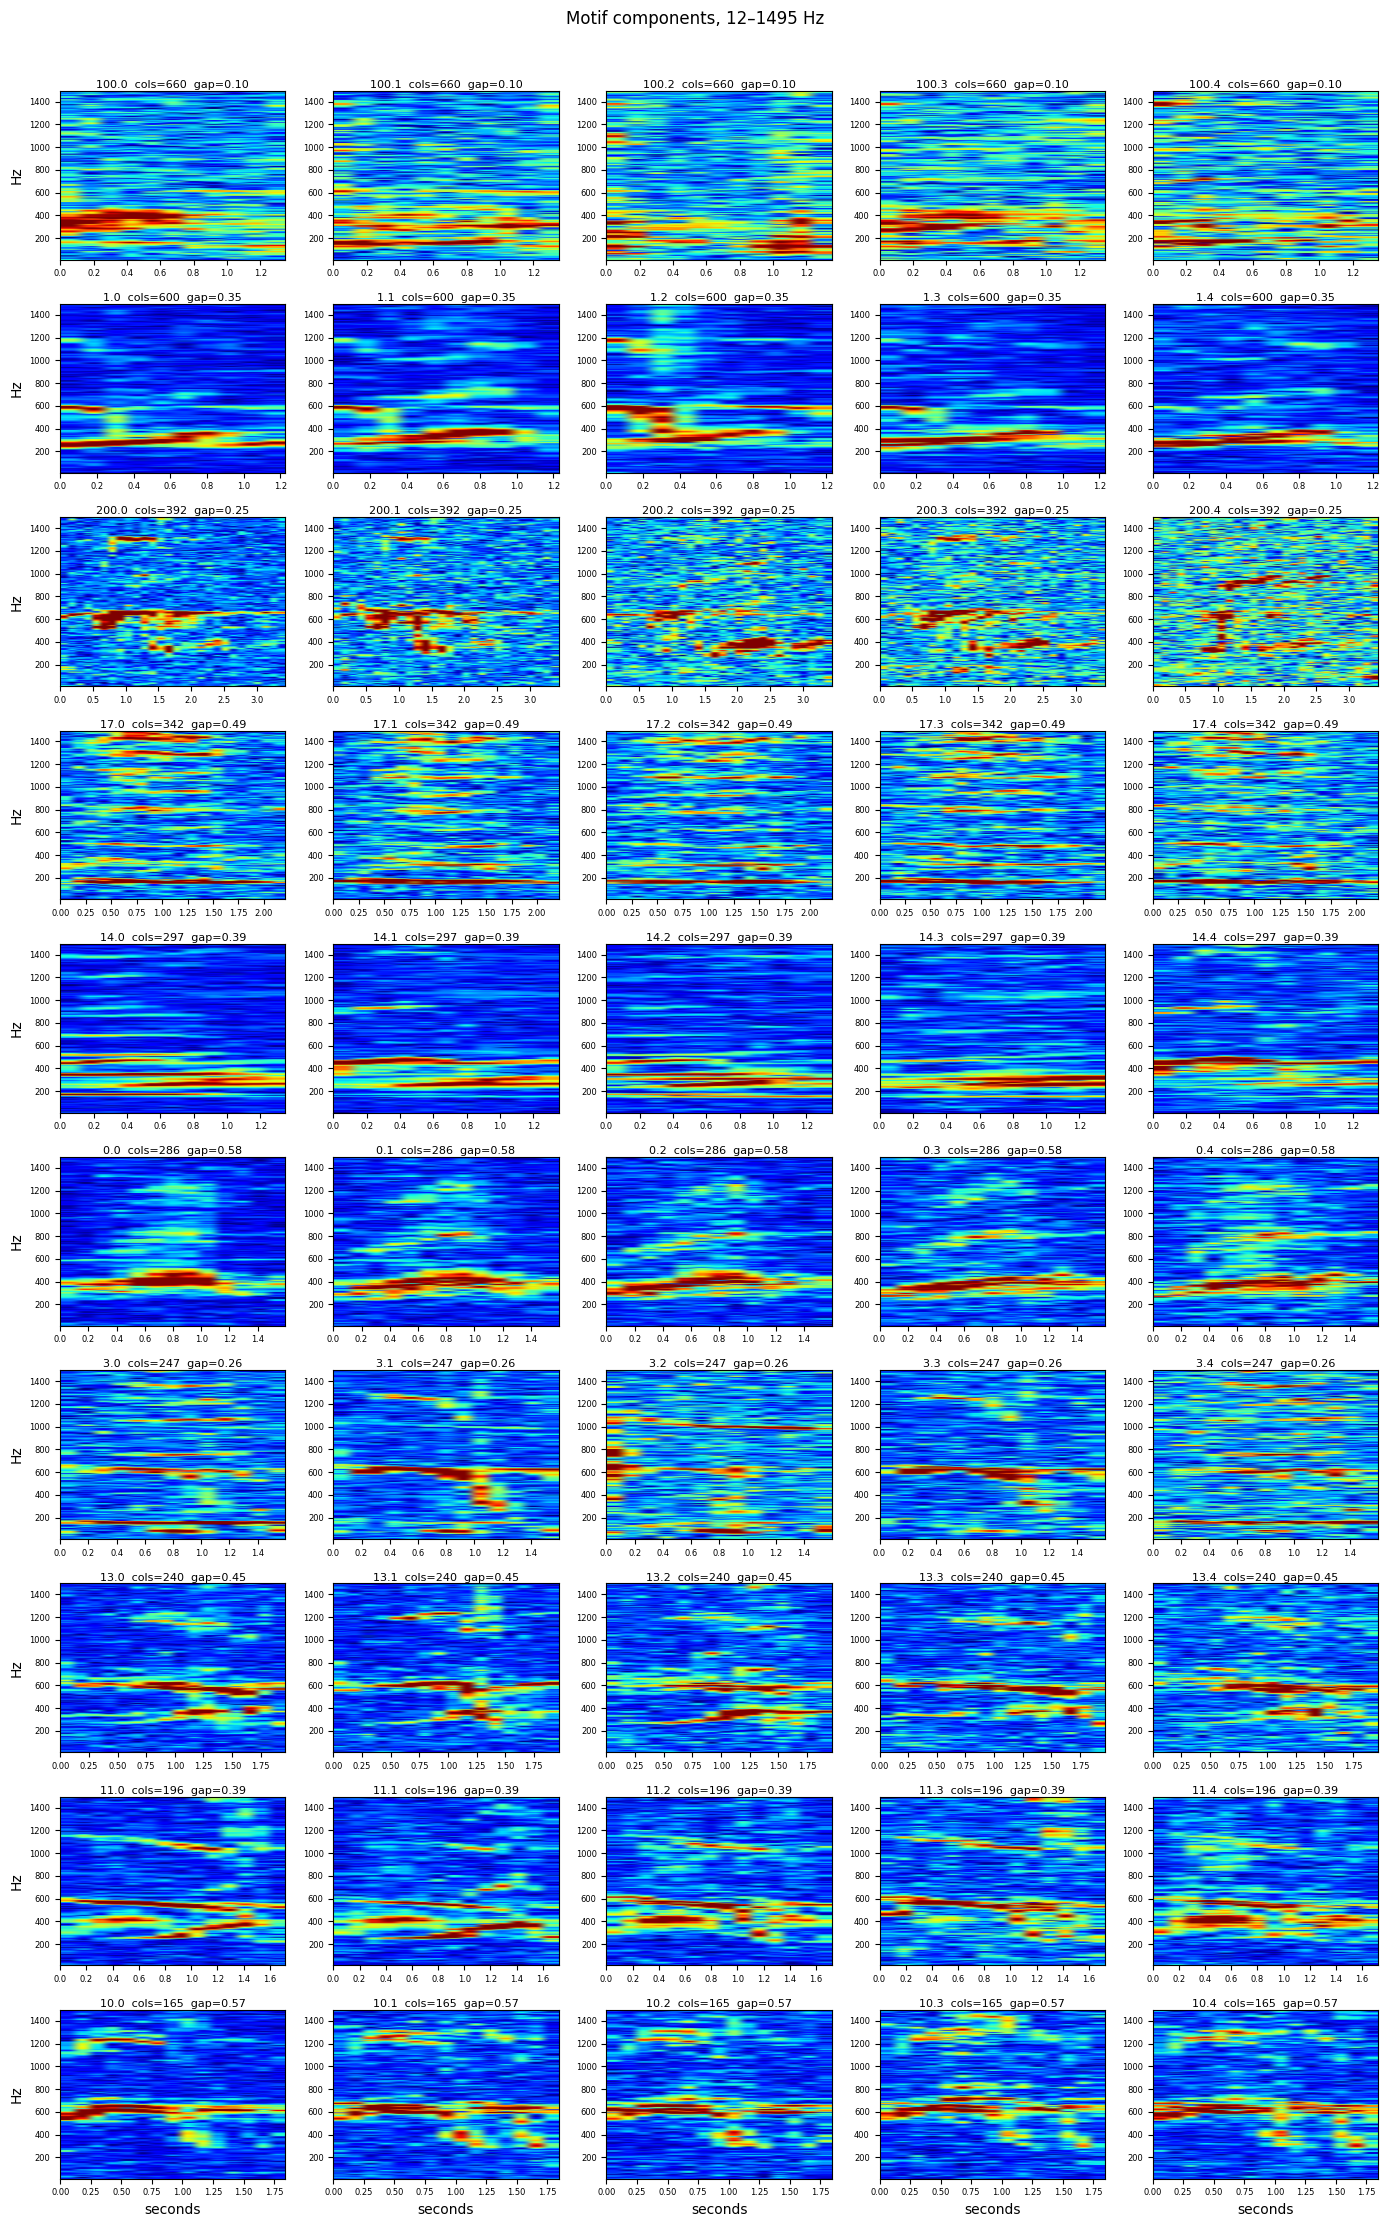

In [3]:
freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
sample = np.load(OUT / motifs[0]["path"])
n_freq = int(sample.shape[-2])
freqs = freq_axis[i0 : i0 + n_freq]
band = np.flatnonzero(freqs <= 1500.0)
band_lo, band_hi = int(band[0]), int(band[-1]) + 1
f_lo, f_hi = float(freqs[band_lo]), float(freqs[band_hi - 1])
panels = []
for row in sorted(motifs, key=lambda item: -item["n_columns"]):
    atom = np.load(OUT / row["path"])
    components = atom if atom.ndim == 3 else atom[None, ...]
    for index, component in enumerate(components):
        panels.append((row, index, component))
ncols = 5
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.2 * nrows))
axes = np.atleast_2d(axes)
for panel, (row, index, component) in enumerate(panels):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    shown = display_from_spwhiten(component)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    if not np.isfinite(lo) or hi <= lo:
        lo, hi = float(np.min(shown)), float(np.max(shown))
    extent = [0.0, component.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(
        f"{row['motif_id']}.{index}  cols={row['n_columns']}  gap={row['mean_gap']:.2f}",
        fontsize=8,
        pad=2,
    )
    ax.tick_params(labelsize=6)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(panels), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle(f"Motif components, {f_lo:.0f}–{f_hi:.0f} Hz", y=1.01)
fig.tight_layout()
plt.show()
